In [37]:
import pandas as pd
import numpy as np

df = pd.read_csv("./ia_tweets.csv")

df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


In [38]:
df.dtypes

ID                           int64
text                           str
polarity                       str
favorite_count               int64
retweet_count                int64
user_followers_count         int64
user_friends_count           int64
user_favourites_count        int64
user_statuses_count          int64
user_verified                int64
user_has_extended_profile    int64
user_is_translator           int64
user_protected               int64
user_default_profile         int64
dtype: object

In [39]:
from langdetect import detect, DetectorFactory

DetectorFactory.seed = 0

df['idioma'] = df['text'].apply(detect)

df = df[df["idioma"] == "es"]

df = df.drop(columns=["ID","user_has_extended_profile", "user_is_translator", "user_protected", "idioma"])

In [40]:
def filtrar_por_polaridad(field):
    return df[df["polarity"] == field]

cant_negativos = len(filtrar_por_polaridad("N"))
cant_neutros = len(filtrar_por_polaridad("NEU"))
cant_positivos =  len(filtrar_por_polaridad("P"))

print('Cantidad de tweets: ', len(df))
print('Tweets Negativos: ', cant_negativos, ', Neutros' , cant_neutros,', Positivos', cant_positivos)

# Cantidad de datos desbalanceada, se tiene mucho mas datos neutros que negativos o positivos.

Cantidad de tweets:  3660
Tweets Negativos:  551 , Neutros 2417 , Positivos 692


In [41]:
cantidad_na = df.isna().sum()
print(cantidad_na)

#(cantidad_negativos_columna("favorite_count"))

# No hay nulls o valores

text                     0
polarity                 0
favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


In [42]:
cantidad_negativos = (df.select_dtypes(include='number') < 0).sum()
print(cantidad_negativos)

favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


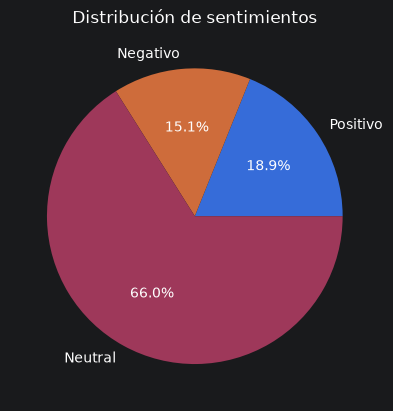

In [43]:
import matplotlib.pyplot as plt

# Datos
clases = ['Positivo', 'Negativo', 'Neutral']
cantidades = [cant_positivos, cant_negativos, cant_neutros]

# Crear gráfico
plt.pie(cantidades, labels=clases, autopct='%1.1f%%')
plt.title('Distribución de sentimientos')
plt.show()

4.1519125683060105
2243
0


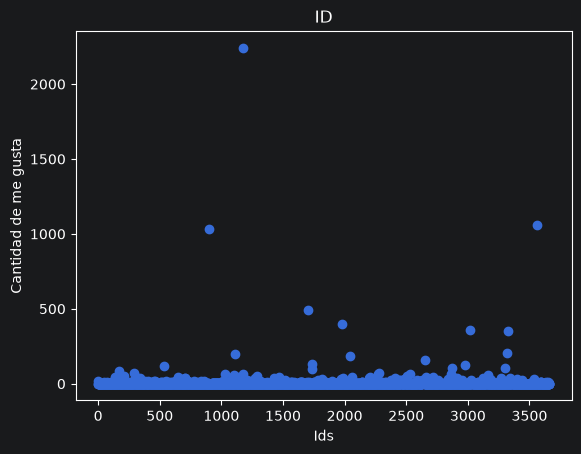

In [44]:
print(df["favorite_count"].mean())
print(df["favorite_count"].max())
print(df["favorite_count"].min())

plt.scatter(range(0,len(df)), df['favorite_count'])

plt.xlabel('Ids')
plt.ylabel('Cantidad de me gusta')
plt.title('ID')

plt.show()

0.9606557377049181
502
0


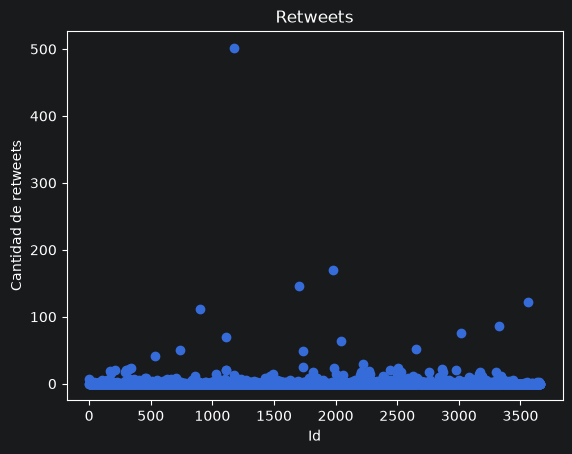

In [45]:
print(df["retweet_count"].mean())
print(df["retweet_count"].max())
print(df["retweet_count"].min())

plt.scatter(range(0,len(df)), df['retweet_count'])

plt.xlabel('Id')
plt.ylabel('Cantidad de retweets')
plt.title('Retweets')

plt.show()

Cantidad de tweets positivo con interaccion:  172
Cantidad de tweets negativos con interaccion:  139
Media de interacciones en positivos:  6.726878612716763
Media de interacciones en negativos:  3.8747731397459164


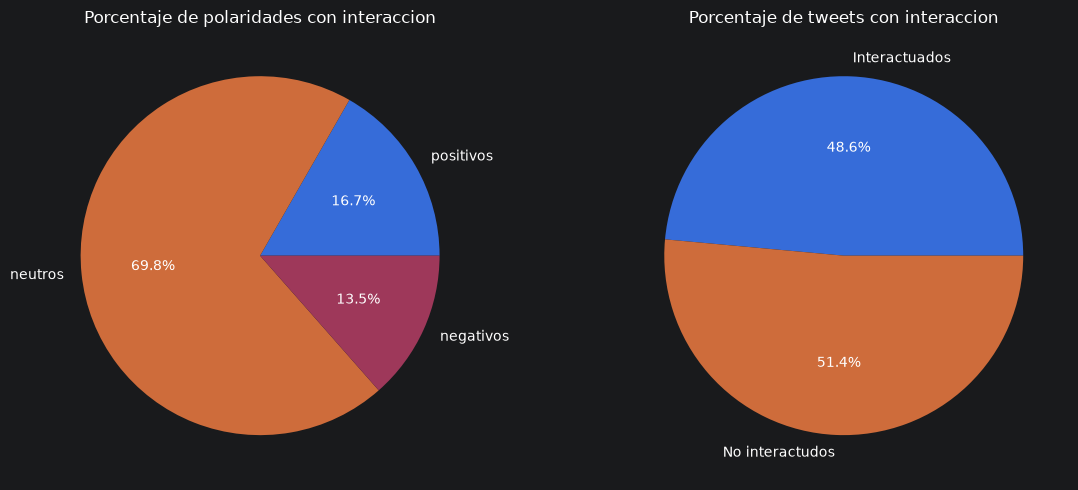

In [46]:
df['tweet_interactions'] = df['favorite_count'] + df['retweet_count']

tweets_con_interaccion = (df['tweet_interactions'] > 0).sum()
tweets_sin_interaccion = (df['tweet_interactions'] == 0).sum()

positivos_con_interaccion = (df[df['polarity'] == 'P']['tweet_interactions'] > 1).sum()
neutros_con_interaccion = (df[df['polarity'] == 'NEU']['tweet_interactions'] > 1).sum()
negativos_con_interaccion = (df[df['polarity'] == 'N']['tweet_interactions'] > 1).sum()
interaccion_positivos_media = df[df['polarity'] == 'P']['tweet_interactions'].mean()
interaccion_negativos_media = df[df['polarity'] == 'N']['tweet_interactions'].mean()

print("Cantidad de tweets positivo con interaccion: ", positivos_con_interaccion)
print("Cantidad de tweets negativos con interaccion: ", negativos_con_interaccion)
print("Media de interacciones en positivos: ", interaccion_positivos_media)
print("Media de interacciones en negativos: ", interaccion_negativos_media)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].pie([positivos_con_interaccion, neutros_con_interaccion, negativos_con_interaccion], labels=["positivos", "neutros", "negativos"], autopct='%1.1f%%')
ax[0].set_title('Porcentaje de polaridades con interaccion')

ax[1].pie([tweets_con_interaccion, tweets_sin_interaccion],
  labels=["Interactuados", "No interactudos"], autopct='%1.1f%%')
ax[1].set_title('Porcentaje de tweets con interaccion')

plt.tight_layout()
plt.show()

In [47]:
 #text
#polarity
#favorite_count
#retweet_count
#user_followers_count
#user_friends_count
#user_favourites_count         TEST (Likes que dio)
#user_statuses_count           TEST (Publicaciones y comentarios suyos)
#user_verified                 TEST
#user_default_profile          TEST (Pagina de perfil default)

import unicodedata

def contar_emojis(texto):
    return sum(1 for caracter in str(texto) if unicodedata.category(caracter) == 'So')

df["length"] = df['text'].apply(lambda texto: len(texto.split()))
df["hashtag_count"] = df['text'].apply(lambda texto: texto.count('#'))
df["mention_count"] = df['text'].apply(lambda texto: texto.count('@'))
df["url_count"] = df['text'].apply(lambda texto: texto.count('http'))
df["punctuation_count"] = df['text'].apply(lambda texto: texto.count('?') + texto.count('!'))
df['emoji_count'] = df['text'].apply(contar_emojis)

# :url: :mencion:

#Campos extra
#Longitud (palabras)
#Cantidad de hashtags
#Cantidad de usuarios mencionados
#Cantidad de emojis
#Cantidad de urls
#Cantidad de signos de exclamacion/interrogacion

In [48]:
df["text"] = df["text"].str.replace(r"http\S+|www\.\S+", "URL", regex=True)
df["text"] = df["text"].str.replace(r"@\w+", "MENCION", regex=True)

df.head()

,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_default_profile,tweet_interactions,length,hashtag_count,mention_count,url_count,punctuation_count,emoji_count
0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,0,28,44,0,0,1,0,0
1,"MENCION Eso es imposible. Y sí, va a generar u...",N,1,0,685,851,169490,128555,0,1,1,41,0,1,0,0,0
2,MENCION Lo disruptivo es que tras años de deci...,NEU,1,0,685,851,169490,128555,0,1,1,39,0,1,0,0,0
3,"MENCION ¿""Prohibición del uso comercial de las...",N,0,0,4877,538,6123,3156,0,0,0,17,0,1,0,1,0
4,MENCION Cómo se está estudiando prohibir chatG...,NEU,0,0,15936,2395,66945,68578,0,0,0,39,0,1,0,1,0


In [49]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["polarity"])
y = df["polarity"]

# 60% para train y 40% para test y validacion
X_train, X_test_val, y_train, y_test_val = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Segunda división: separar test y validación
X_test, X_val, y_test, y_val = train_test_split(
    X_test_val, y_test_val,
    test_size=0.5,
    random_state=42,
    stratify=y_test_val
)

print(len(X_train)/len(df))

0.6


In [50]:
from sklearn.preprocessing import StandardScaler

number_columns = ["favorite_count","retweet_count","user_followers_count", "user_friends_count", "user_favourites_count", "user_statuses_count", "tweet_interactions", "hashtag_count", "mention_count"]

scaler = StandardScaler()

X_train[number_columns] = scaler.fit_transform(X_train[number_columns])

y_train = pd.get_dummies(y_train, columns=["polarity"], dtype=int, drop_first=True)

X_train.head()
y_train.head()

,NEU,P
1468,1,0
3145,1,0
2137,1,0
3883,1,0
2562,1,0


In [51]:
from sklearn.base import BaseEstimator, TransformerMixin
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
import string

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')
stop_words = set(stopwords.words('spanish'))

class TextCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, method=None):
        self.method = method

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # Inicializamos dentro de transform para evitar errores de multiprocessing
        stop_words = set(stopwords.words('spanish'))
        punctuation = set(string.punctuation)
        stemmer = PorterStemmer()
        lemmatizer = WordNetLemmatizer()

        clean_X = []
        for text in X:
            # 1. Minúsculas y Tokenización
            tokens = nltk.word_tokenize(text.lower())

            # 2. Remover Stopwords y Puntuación
            tokens = [t for t in tokens if t not in stop_words and t not in punctuation]

            # 3. Reducción a raíz (Stemming o Lemmatization)
            if self.method == 'stem':
                tokens = [stemmer.stem(t) for t in tokens]
            elif self.method == 'lemma':
                tokens = [lemmatizer.lemmatize(t) for t in tokens]

            clean_X.append(" ".join(tokens))
        return clean_X

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\lucas\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\lucas\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\lucas\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [52]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

cleaner = TextCleaner("lemma")

vectores = cleaner.transform(df["text"])
vectorizer_BoW = CountVectorizer()
vectorizer_Tfidf = TfidfVectorizer()


matriz_BoW = vectorizer_BoW.fit_transform(vectores)
matriz_Tfidf = vectorizer_Tfidf.fit_transform(vectores)

print(vectorizer_BoW.get_feature_names_out())
#print(vectores_Tfidf.shape)

['00' '000' '003' ... '𝙀𝙣𝙩𝙧𝙚𝙥𝙖𝙧𝙦𝙪𝙚𝙨' '𝙈𝙤𝙣𝙩𝙚𝙨𝙪𝙧' '𝙈𝙤𝙣𝙩𝙞𝙚𝙡']


In [53]:
from sentence_transformers import SentenceTransformer # <- Estandar para Embeddings

class EmbeddingTransformer(BaseEstimator, TransformerMixin):
    # Caché a nivel de CLASE: sobrevive a los clones que arma GridSearchCV
    # Clave: (nombre_del_modelo, texto) -> vector
    _cache = {}

    def __init__(self, model_name='paraphrase-multilingual-MiniLM-L12-v2'):
        self.model_name = model_name

    def fit(self, X, y=None):
        # Cargamos el modelo aquí para evitar errores de serialización
        if not hasattr(self, "model_"):
            self.model_ = SentenceTransformer(self.model_name)
        return self

    def transform(self, X):
        # Convertimos la lista de textos en una matriz de vectores (Embeddings)
        # Esto implementa implícitamente el "Mean Pooling"
        # Solo calculamos los textos que aún no están en la caché
        texts = list(X)
        faltantes = [t for t in texts if (self.model_name, t) not in self._cache]
        if faltantes:
            vectores = self.model_.encode(faltantes, show_progress_bar=False)
            for t, v in zip(faltantes, vectores):
                self._cache[(self.model_name, t)] = v
        return np.array([self._cache[(self.model_name, t)] for t in texts])

embedding = EmbeddingTransformer()

In [54]:
embedding.fit(df["text"])
text = embedding.transform(df["text"])
print(text.shape)
print(text)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2830.47it/s]


(3660, 384)
[[ 0.15161385  0.13791269 -0.15399659 ... -0.23173821  0.18059729
   0.07939073]
 [-0.05797388 -0.24207357  0.1003264  ... -0.01575597  0.2149977
  -0.11276339]
 [-0.06540345 -0.17857747  0.19099697 ...  0.08109542  0.40129176
   0.07221729]
 ...
 [-0.26395094 -0.03915968 -0.14702237 ... -0.07476871 -0.2275236
   0.05211054]
 [-0.06131364 -0.00176563  0.1604707  ... -0.01875054 -0.07580694
  -0.18729645]
 [ 0.05583214 -0.19120209 -0.01426135 ...  0.01423992 -0.0706326
   0.055838  ]]


In [55]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from tensorflow import keras
from tensorflow.keras import layers
from scikeras.wrappers import KerasClassifier

X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])

X_train_raw = X.loc[X_trval.index]
y_train_raw = y.loc[y_trval.index]

num_cols = number_columns[:7]

preprocessor = ColumnTransformer([
    ("text", Pipeline([
        ("cleaner", TextCleaner()),
        ("embedding", EmbeddingTransformer()),
    ]), "text"),
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
])
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from tensorflow import keras
from tensorflow.keras import layers
from scikeras.wrappers import KerasClassifier

# Train + val juntos: GridSearchCV arma sus propios folds de validación
X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])

X_train_raw = X.loc[X_trval.index]
y_train_raw = y.loc[y_trval.index]

num_cols = number_columns[:7]

preprocessor = ColumnTransformer([
    ("text", Pipeline([
        ("cleaner", TextCleaner()),
        ("embedding", EmbeddingTransformer()),
    ]), "text"),
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
])

def build_model(meta, n_units=128, n_layers=1, dropout=0.3,
                activation="relu", learning_rate=1e-3):
    model = keras.Sequential()
    model.add(keras.Input(shape=(meta["n_features_in_"],)))
    for _ in range(n_layers):
        model.add(layers.Dense(n_units, activation=activation))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(meta["n_classes_"], activation="softmax"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

clf = KerasClassifier(
    model=build_model,
    epochs=100,               # alto, el early stopping corta antes
    batch_size=32,
    validation_split=0.2,     # necesario para que EarlyStopping tenga val_loss
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )],
    verbose=0,
)

pipeline_nn = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", clf),
])

param_grid = {
    "classifier__model__n_units": [64, 128, 256],
    "classifier__model__n_layers": [1, 2],
    "classifier__model__dropout": [0.0, 0.3],
    "classifier__model__learning_rate": [1e-2, 1e-3],
    "classifier__batch_size": [32, 64],
}

grid = GridSearchCV(
    pipeline_nn,
    param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=1,
    verbose=2,
    refit=True,               # reentrena el mejor modelo con todo X_train_raw
)

grid.fit(X_train_raw, y_train_raw)

print("Mejores parámetros:", grid.best_params_)
print("Mejor score (CV):", grid.best_score_)
best_model = grid.best_estimator_

Fitting 3 folds for each of 48 candidates, totalling 144 fits


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2074.57it/s]


[CV] END classifier__batch_size=32, classifier__model__dropout=0.0, classifier__model__learning_rate=0.01, classifier__model__n_layers=1, classifier__model__n_units=64; total time=  20.7s


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2242.08it/s]


[CV] END classifier__batch_size=32, classifier__model__dropout=0.0, classifier__model__learning_rate=0.01, classifier__model__n_layers=1, classifier__model__n_units=64; total time=   7.9s


...

[CV] END classifier__batch_size=64, classifier__model__dropout=0.3, classifier__model__learning_rate=0.001, classifier__model__n_layers=2, classifier__model__n_units=256; total time=  48.3s


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1942.55it/s]


[CV] END classifier__batch_size=64, classifier__model__dropout=0.3, classifier__model__learning_rate=0.001, classifier__model__n_layers=2, classifier__model__n_units=256; total time=  10.1s


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1771.87it/s]


Mejores parámetros: {'classifier__batch_size': 32, 'classifier__model__dropout': 0.3, 'classifier__model__learning_rate': 0.001, 'classifier__model__n_layers': 2, 'classifier__model__n_units': 64}
Mejor score (CV): 0.6055975469770766


Mejores parámetros: {'classifier__batch_size': 32, 'classifier__model__dropout': 0.3, 'classifier__model__learning_rate': 0.001, 'classifier__model__n_layers': 2, 'classifier__model__n_units': 64}

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2338.48it/s]


units=   4 | F1 train=0.666 | F1 val=0.656 | brecha=+0.010
units=   8 | F1 train=0.782 | F1 val=0.778 | brecha=+0.004
units=  16 | F1 train=0.899 | F1 val=0.887 | brecha=+0.012
units=  32 | F1 train=0.976 | F1 val=0.969 | brecha=+0.007
units=  64 | F1 train=0.998 | F1 val=0.995 | brecha=+0.003
units= 128 | F1 train=1.000 | F1 val=1.000 | brecha=+0.000
units= 256 | F1 train=1.000 | F1 val=1.000 | brecha=+0.000
units= 512 | F1 train=1.000 | F1 val=1.000 | brecha=-0.000


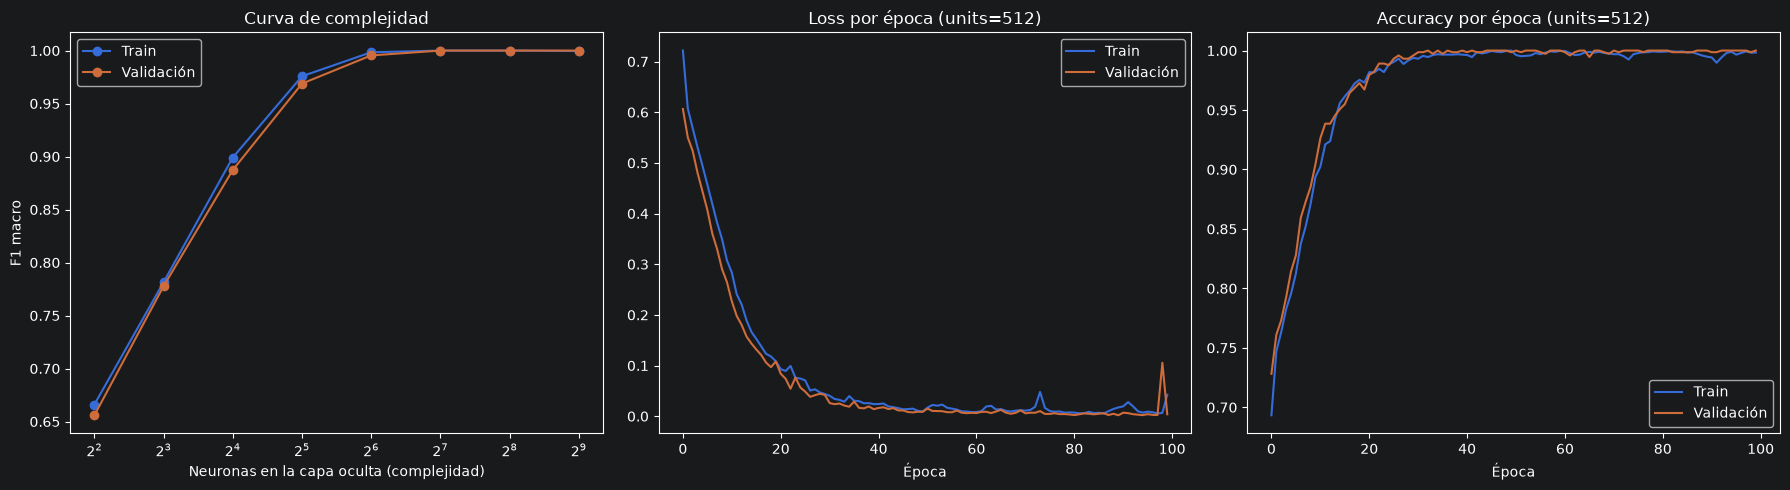

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import f1_score
from sklearn.preprocessing import LabelEncoder
from tensorflow import keras
from tensorflow.keras import layers

# --- Features precalculadas una sola vez (el embedding es lo costoso) ---
prep = clone(preprocessor)
Xtr = prep.fit_transform(X_train_raw)
Xva = prep.transform(X_val)          # X_val no fue escalado antes, entra crudo

le = LabelEncoder().fit(y_train_raw)
ytr, yva = le.transform(y_train_raw), le.transform(y_val)

def construir(units=128):
    modelo = keras.Sequential([
        keras.Input(shape=(Xtr.shape[1],)),
        layers.Dense(units, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(len(le.classes_), activation="softmax"),
    ])
    modelo.compile(optimizer="adam",
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
    return modelo

def curva_complejidad(unidades=(4, 8, 16, 32, 64, 128, 256, 512),
                      epochs=10, seed=42):
    f1_train, f1_val, historias = [], [], {}
    for u in unidades:
        keras.utils.set_random_seed(seed)
        m = construir(u)
        h = m.fit(Xtr, ytr, validation_data=(Xva, yva),
                  epochs=epochs, batch_size=32, verbose=0)
        historias[u] = h.history
        f1_train.append(f1_score(ytr, m.predict(Xtr, verbose=0).argmax(1), average="macro"))
        f1_val.append(f1_score(yva, m.predict(Xva, verbose=0).argmax(1), average="macro"))
        print(f"units={u:>4} | F1 train={f1_train[-1]:.3f} | F1 val={f1_val[-1]:.3f} "
              f"| brecha={f1_train[-1]-f1_val[-1]:+.3f}")

    fig, ax = plt.subplots(1, 3, figsize=(18, 5))

    # 1) Curva de complejidad
    ax[0].plot(unidades, f1_train, "o-", label="Train")
    ax[0].plot(unidades, f1_val, "o-", label="Validación")
    ax[0].set_xscale("log", base=2)
    ax[0].set_xlabel("Neuronas en la capa oculta (complejidad)")
    ax[0].set_ylabel("F1 macro")
    ax[0].set_title("Curva de complejidad")
    ax[0].legend()

    # 2 y 3) Loss y accuracy por época del modelo más grande
    h = historias[unidades[-1]]
    ax[1].plot(h["loss"], label="Train")
    ax[1].plot(h["val_loss"], label="Validación")
    ax[1].set_title(f"Loss por época (units={unidades[-1]})")
    ax[1].set_xlabel("Época"); ax[1].legend()

    ax[2].plot(h["accuracy"], label="Train")
    ax[2].plot(h["val_accuracy"], label="Validación")
    ax[2].set_title(f"Accuracy por época (units={unidades[-1]})")
    ax[2].set_xlabel("Época"); ax[2].legend()

    plt.tight_layout()
    plt.show()


curva_complejidad()

===== Test =====
Accuracy:            0.7555
Precision (macro):   0.7256
Precision (weighted):0.7488
Recall (macro):      0.5969
F1 (macro):          0.6373
F1 (weighted):       0.7363
ROC-AUC (OvR macro): 0.8271

Reporte por clase:

              precision    recall  f1-score   support

           N       0.65      0.44      0.52       110
         NEU       0.77      0.92      0.84       484
           P       0.76      0.43      0.55       138

    accuracy                           0.76       732
   macro avg       0.73      0.60      0.64       732
weighted avg       0.75      0.76      0.74       732



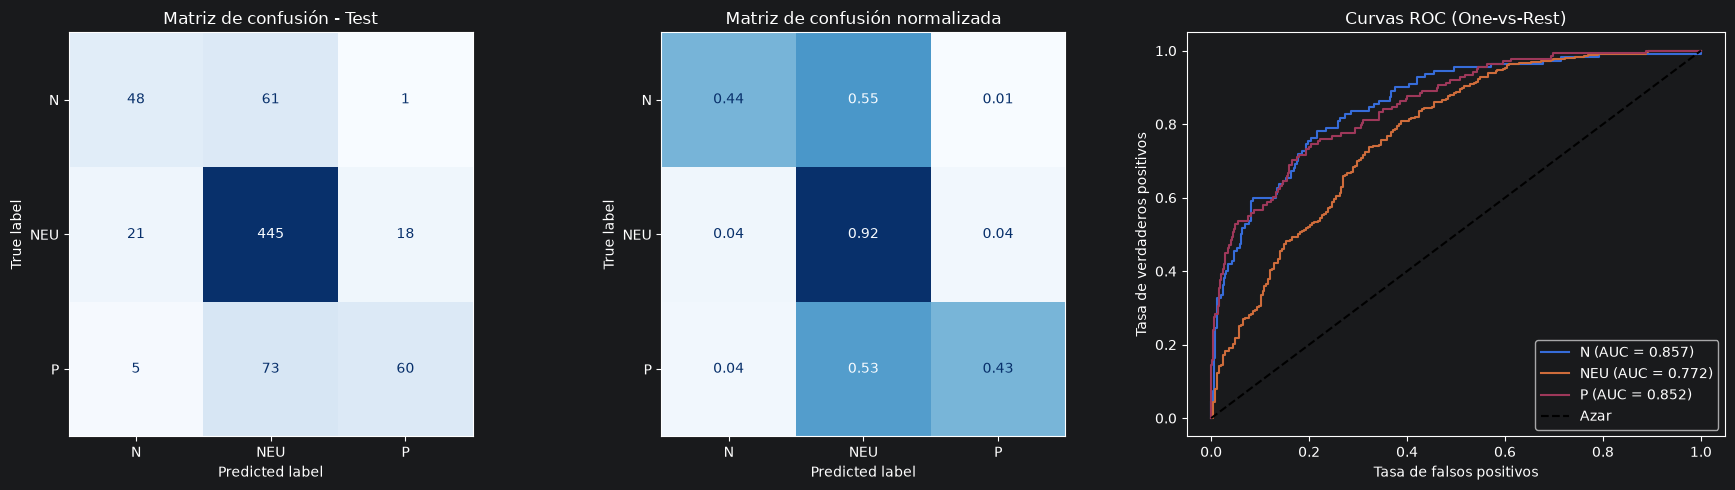

In [65]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

def evaluar(pipeline, X_eval, y_eval, nombre="Test"):
    clases = ['N', 'NEU', 'P']   # ['N', 'NEU', 'P']
    y_pred = pipeline.predict(X_eval)
    y_proba = pipeline.predict_proba(X_eval)               # columnas en el orden de `clases`

    # ---------- Métricas ----------
    print(f"===== {nombre} =====")
    print(f"Accuracy:            {accuracy_score(y_eval, y_pred):.4f}")
    print(f"Precision (macro):   {precision_score(y_eval, y_pred, average='macro', zero_division=0):.4f}")
    print(f"Precision (weighted):{precision_score(y_eval, y_pred, average='weighted', zero_division=0):.4f}")
    print(f"Recall (macro):      {recall_score(y_eval, y_pred, average='macro', zero_division=0):.4f}")
    print(f"F1 (macro):          {f1_score(y_eval, y_pred, average='macro', zero_division=0):.4f}")
    print(f"F1 (weighted):       {f1_score(y_eval, y_pred, average='weighted', zero_division=0):.4f}")
    print(f"ROC-AUC (OvR macro): {roc_auc_score(y_eval, y_proba, multi_class='ovr', average='macro', labels=clases):.4f}")
    print("\nReporte por clase:\n")
    print(classification_report(y_eval, y_pred, labels=clases, zero_division=0))

    # ---------- Gráficos ----------
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))

    # Matriz de confusión (cantidades)
    cm = confusion_matrix(y_eval, y_pred, labels=clases)
    ConfusionMatrixDisplay(cm, display_labels=clases).plot(ax=ax[0], cmap="Blues", colorbar=False)
    ax[0].set_title(f"Matriz de confusión - {nombre}")

    # Matriz de confusión (normalizada por fila = recall por clase)
    cm_norm = confusion_matrix(y_eval, y_pred, labels=clases, normalize="true")
    ConfusionMatrixDisplay(cm_norm, display_labels=clases).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f")
    ax[1].set_title("Matriz de confusión normalizada")

    # Curvas ROC One-vs-Rest
    y_bin = label_binarize(y_eval, classes=clases)
    for i, clase in enumerate(clases):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba[:, i])
        ax[2].plot(fpr, tpr, label=f"{clase} (AUC = {auc(fpr, tpr):.3f})")
    ax[2].plot([0, 1], [0, 1], "k--", label="Azar")
    ax[2].set_xlabel("Tasa de falsos positivos")
    ax[2].set_ylabel("Tasa de verdaderos positivos")
    ax[2].set_title("Curvas ROC (One-vs-Rest)")
    ax[2].legend(loc="lower right")

    plt.tight_layout()
    plt.show()


evaluar(best_model, X_test, y_test, "Test")

In [66]:
# --- Prueba manual del pipeline ---
tweets = [
    "A veces funciona, a veces no",
    "Nos puede llegar a sacar el trabajo, es un peligro",
    "Es una buena herramienta",
]

# Valores numéricos neutros: mediana del train (no 0)
medianas = X_train_raw[num_cols].median()

entrada = pd.DataFrame({"text": tweets})
for col in num_cols:
    entrada[col] = medianas[col]

clf = best_model.named_steps["classifier"]
preds = best_model.predict(entrada)
probas = best_model.predict_proba(entrada)

resultado = pd.DataFrame(probas, columns=clf.classes_).round(4)
resultado.insert(0, "tweet", tweets)
resultado.insert(1, "prediccion", preds)
print(resultado.to_string(index=False))

                                             tweet prediccion      N    NEU      P
                      A veces funciona, a veces no        NEU 0.3281 0.6191 0.0528
Nos puede llegar a sacar el trabajo, es un peligro          N 0.6832 0.3033 0.0135
                          Es una buena herramienta        NEU 0.0026 0.5189 0.4785


In [ ]:
keras.utils.set_random_seed(42)
m = construir(512)
h = m.fit(Xtr, ytr, validation_data=(Xva, yva),
          epochs=100, batch_size=32, verbose=0)

# f1_train / f1_val son locales de curva_complejidad(): acá usamos variables propias
f1_m_train = f1_score(ytr, m.predict(Xtr, verbose=0).argmax(1), average="macro")
f1_m_val = f1_score(yva, m.predict(Xva, verbose=0).argmax(1), average="macro")
print(f"units=512 | F1 train={f1_m_train:.3f} | F1 val={f1_m_val:.3f} "
      f"| brecha={f1_m_train - f1_m_val:+.3f}")


                                             tweet prediccion      N    NEU      P
                      A veces funciona, a veces no          N 0.9949 0.0051 0.0000
Nos puede llegar a sacar el trabajo, es un peligro          N 1.0000 0.0000 0.0000
                          Es una buena herramienta          P 0.0000 0.4435 0.5565
===== Test - modelo 512 =====
Accuracy:            0.7049
Precision (macro):   0.6305
Precision (weighted):0.7001
Recall (macro):      0.5934
F1 (macro):          0.6071
F1 (weighted):       0.6993
ROC-AUC (OvR macro): 0.7952

Reporte por clase:

              precision    recall  f1-score   support

           N       0.47      0.48      0.48       110
         NEU       0.76      0.82      0.79       484
           P       0.65      0.48      0.55       138

    accuracy                           0.70       732
   macro avg       0.63      0.59      0.61       732
weighted avg       0.70      0.70      0.70       732



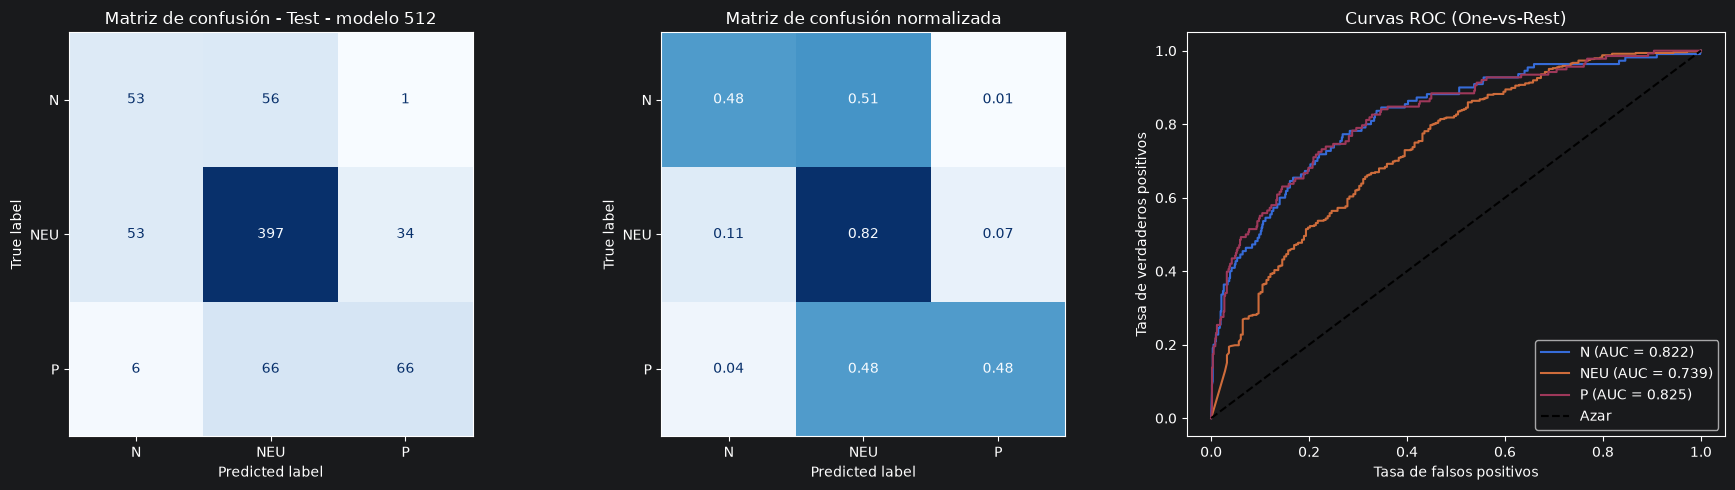

In [71]:
# --- Prueba manual con el modelo de la celda anterior (m, 512 neuronas) ---
# Requiere: celda del TextCleaner/EmbeddingTransformer, celda 19 (crea `prep` y `le`)
# y la celda que entrena `m`.

MEDIANAS = X_train_raw[num_cols].median()   # valores CRUDOS: prep se encarga de imputar y escalar

def predecir_tweets(tweets, modelo=m):
    """Probabilidades por clase para una lista de textos, usando el preprocesamiento de entrenamiento."""
    entrada = pd.DataFrame({"text": list(tweets)})
    for col in num_cols:
        entrada[col] = MEDIANAS[col]

    X_new = prep.transform(entrada)            # mismo camino que Xtr / Xva
    proba = modelo.predict(X_new, verbose=0)   # softmax -> (n, n_clases)
    idx = proba.argmax(axis=1)

    resultado = pd.DataFrame(proba, columns=le.classes_).round(4)
    resultado.insert(0, "tweet", list(tweets))
    resultado.insert(1, "prediccion", le.inverse_transform(idx))
    return resultado

tweets = [
    "A veces funciona, a veces no",
    "Nos puede llegar a sacar el trabajo, es un peligro",
    "Es una buena herramienta",
]

print(predecir_tweets(tweets).to_string(index=False))


# --- El mismo modelo, envuelto para poder reusar evaluar() de la celda de métricas ---
class ModeloKeras:
    """Envuelve (preprocessor ya ajustado + modelo Keras) con la API de sklearn."""

    def __init__(self, prep, modelo, clases):
        self.prep = prep
        self.modelo = modelo
        self.clases = clases

    def predict(self, X):
        proba = self.modelo.predict(self.prep.transform(X), verbose=0)
        return self.clases[proba.argmax(axis=1)]

    def predict_proba(self, X):
        return self.modelo.predict(self.prep.transform(X), verbose=0)

modelo_512 = ModeloKeras(prep, m, le.classes_)

# X_test nunca fue escalado, así que prep.transform lo procesa igual que a Xtr
evaluar(modelo_512, X_test, y_test, "Test - modelo 512")
